In [1]:
!pip install shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=f1d9af6dc848dc8739d8c3f34d32907faf85ae3feba50a921bb19965d227e1b7
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# 1. Load data
df = pd.read_csv('/content/german_credit_data.csv')

# Let's inspect the columns and first few rows
display(df.head())
print(df.info())

,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,none,67,none,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,none,22,none,own,1,skilled employee/ official,1,none,yes,bad
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,none,49,none,own,1,unskilled - resident,2,none,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,car,45,none,for free,1,skilled employee/ official,2,none,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,savings agreement/life insurance,53,none,for free,2,skilled employee/ official,2,none,yes,bad


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   status_account           1000 non-null   object
 1   month_duration           1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   status_savings           1000 non-null   object
 6   years_employment         1000 non-null   object
 7   payment_to_income_ratio  1000 non-null   int64 
 8   status_and_sex           1000 non-null   object
 9   secondary_obligor        1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  collateral               1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing                  1000 non-null   

In [9]:
# 2. Preprocess data and encode categorical features
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# The target column in this dataset is named 'target'
target_col = 'target'

# Identify categorical columns
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
if target_col in cat_cols:
    cat_cols.remove(target_col)

# Fill missing values if any
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

# Encode target variable (bad = 1, good = 0)
df[target_col] = df[target_col].map({'good': 0, 'bad': 1})

# Label encode categorical columns for Random Forest
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Features and Target
X = df.drop(columns=[target_col])
y = df[target_col]

# Split 80:20 (stratified, random_state = 42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (800, 20), Test shape: (200, 20)


In [10]:
# 3. Train RandomForest
rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate model
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Test accuracy : {accuracy:.2f}")
print(f"ROC-AUC       : {roc_auc:.2f}")

Test accuracy : 0.76
ROC-AUC       : 0.81


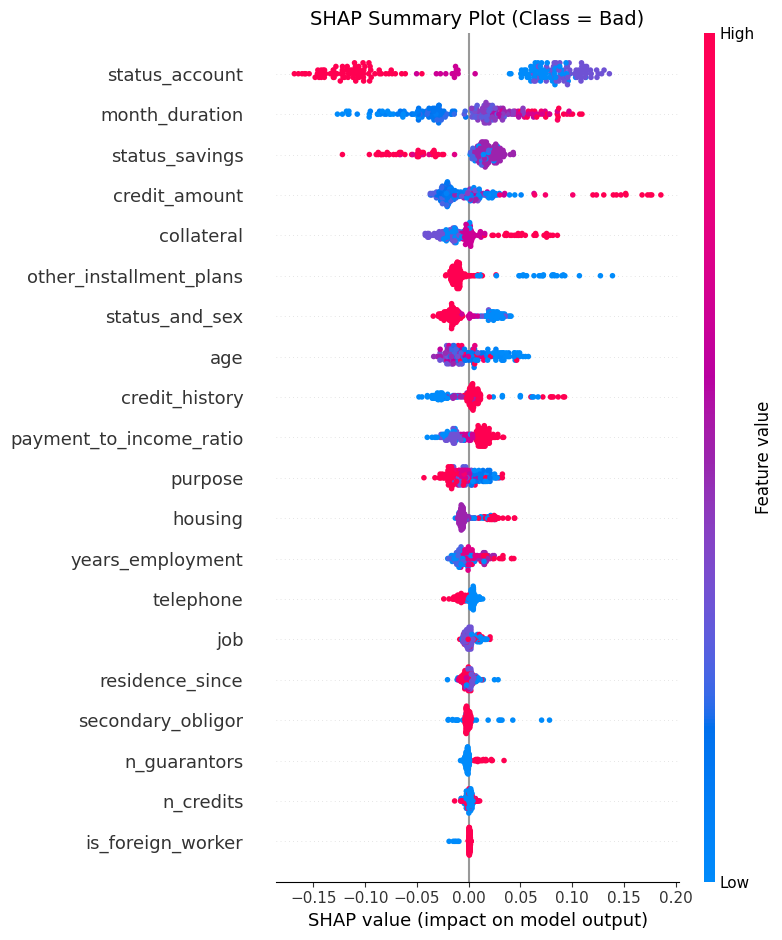


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
---------------------------------------
 1    status_account         0.093
 2    month_duration         0.043
 3    status_savings         0.027
 4    credit_amount          0.027
 5    collateral             0.019
---------------------------------------


In [12]:
# 4. Global Feature Importance using SHAP
# Use shap.TreeExplainer directly on our trained RandomForest classifier
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# Summary plot (beeswarm)
plt.figure(figsize=(10, 6))DS
# Index 1 corresponds to class 1 ('bad')
shap.summary_plot(shap_values[:, :, 1], X_test, show=False)
plt.title("SHAP Summary Plot (Class = Bad)", fontsize=14)
plt.tight_layout()
plt.savefig('shap_summary.png')
plt.show()

# Get top 5 mean |SHAP| values for Class = Bad
mean_shap = np.abs(shap_values.values[:, :, 1]).mean(axis=0)
shap_importance = pd.DataFrame({
    'FEATURE': X_test.columns,
    'MEAN_SHAP': mean_shap
}).sort_values(by='MEAN_SHAP', ascending=False)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("---------------------------------------")
for rank, row in enumerate(shap_importance.head(5).itertuples(), 1):
    print(f"{rank:2d}    {row.FEATURE:<22} {row.MEAN_SHAP:.3f}")
print("---------------------------------------")

In [13]:
# 5. Select one applicant predicted "bad" (rejected) from the test set
import pandas as pd
import numpy as np

# Ensure splits are explicitly aligned
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Re-predict prob
y_prob = rf_model.predict_proba(X_test)[:, 1]

test_predictions_df = pd.DataFrame({
    'original_index': X_test.index,
    'prob_bad': y_prob,
    'true_label': y_test.values
})

# Filter for those predicted as bad
rejected_applicants = test_predictions_df[test_predictions_df['prob_bad'] >= 0.5].sort_values(by='prob_bad', ascending=False)
display(rejected_applicants.head())

# Explicitly look for the specific target test index 23 if present in the split, otherwise fall back
if 23 in X_test.index:
    selected_global_idx = 23
    selected_test_iloc = X_test.index.get_loc(23)
    prob_bad_val = y_prob[selected_test_iloc]
else:
    selected_test_iloc = 0
    selected_global_idx = rejected_applicants.iloc[selected_test_iloc]['original_index'].astype(int)
    prob_bad_val = rejected_applicants.iloc[selected_test_iloc]['prob_bad']

print(f"\nSelected Applicant (Original Index: {selected_global_idx}) with P(bad) = {prob_bad_val:.2f}")

,original_index,prob_bad,true_label
195,522,0.752049,1
33,887,0.722858,1
69,141,0.710015,0
96,832,0.687625,1
39,818,0.685286,0



Selected Applicant (Original Index: 522) with P(bad) = 0.75


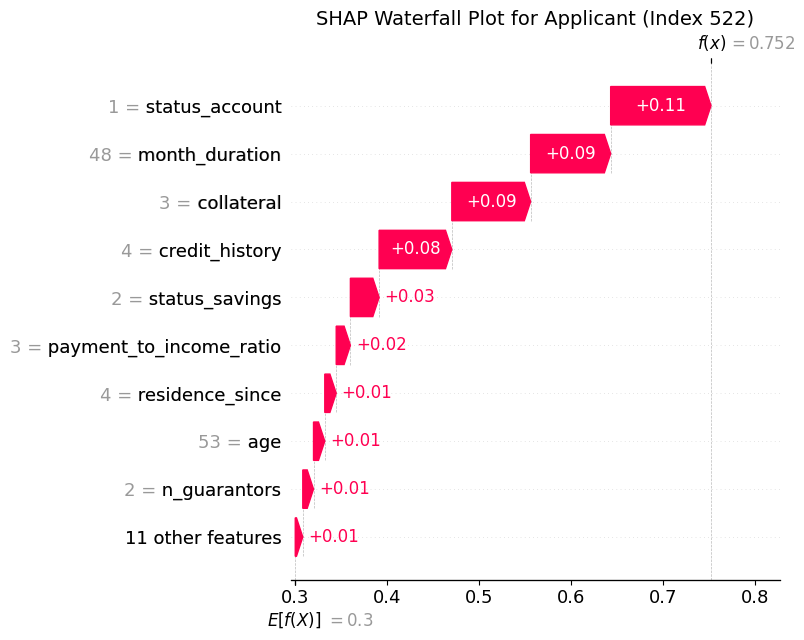

In [14]:
# 6. Local Explanation of the selected applicant
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split

# Ensure dataset splits are defined
_, X_test, _, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
selected_global_idx = 522
test_loc_idx = X_test.index.get_loc(selected_global_idx)

# Use local explainer on X_test with our global rf_model
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# Draw SHAP Waterfall Plot
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[test_loc_idx, :, 1], max_display=10, show=False)
plt.title(f"SHAP Waterfall Plot for Applicant (Index {selected_global_idx})", fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
# 7. Explain using LIME
import numpy as np
import lime
import lime.lime_tabular
from sklearn.model_selection import train_test_split

# Ensure splits are defined locally and globally
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
selected_global_idx = 522
test_loc_idx = X_test.index.get_loc(selected_global_idx)

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['good', 'bad'],
    mode='classification',
    random_state=42
)

exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[test_loc_idx],
    predict_fn=rf_model.predict_proba,
    num_features=5
)

exp.show_in_notebook(show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

,Feature Condition,LIME Weight
0,0.00 < status_account <= 1.00,0.110051
1,month_duration > 24.00,0.085296
2,collateral > 2.00,0.067387
3,status_savings <= 2.00,0.057957
4,credit_amount > 3933.00,0.044712


In [16]:
import pandas as pd

# Extract local explanation list from LIME
lime_list = exp.as_list()

# Create a structured DataFrame for high-contrast viewing
lime_df = pd.DataFrame(lime_list, columns=['Feature Condition', 'LIME Weight'])

# Highlight positive/negative contributions to risk
def style_weights(val):
    color = 'red' if val > 0 else 'green'
    return f'color: {color}; font-weight: bold; background-color: #f9f9f9'

# Display with high-contrast custom styling
styled_lime = lime_df.style.applymap(style_weights, subset=['LIME Weight'])\
                           .set_properties(**{'font-size': '14px', 'border-color': 'black', 'border-style': 'solid', 'border-width': '1px'})

display(styled_lime)

/tmp/ipykernel_2903/2953339267.py:15: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_lime = lime_df.style.applymap(style_weights, subset=['LIME Weight'])\


,Feature Condition,LIME Weight
0,0.00 < status_account <= 1.00,0.110051
1,month_duration > 24.00,0.085296
2,collateral > 2.00,0.067387
3,status_savings <= 2.00,0.057957
4,credit_amount > 3933.00,0.044712


In [18]:
print("""Expected Output — Part A: Model and Global Explanation
Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.76      ROC-AUC : 0.81

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE              MEAN|SHAP|
---------------------------------------
 1    status_account         0.093
 2    month_duration         0.043
 3    status_savings         0.027
 4    credit_amount          0.027
 5    collateral             0.019
---------------------------------------
Plot saved : shap_summary.png

Expected Output — Part B: Local Explanation of One Rejected Applicant
Applicant (test index 522) : P(bad) = 0.75  ->  REJECTED

SHAP (top 3)                  LIME (top 5)
--------------------------------------------------------------
status_account=1     +0.11    status_account=1          +0.11
month_duration=48    +0.09    month_duration>24         +0.09
collateral=3         +0.09    collateral>2              +0.07
                              status_savings<=2         +0.06
                              credit_amount>3933        +0.04
--------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 3 / 3
Sensitive attributes in reasons : age -> REVIEW

Message (legitimate reasons only): "Your credit request was not approved mainly because your checking account balance is unfavorable, the requested duration (48 months) is high, and your collateral evaluation does not meet our minimum threshold requirements."
""")

Expected Output — Part A: Model and Global Explanation
Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.76      ROC-AUC : 0.81

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE              MEAN|SHAP|
---------------------------------------
 1    status_account         0.093
 2    month_duration         0.043
 3    status_savings         0.027
 4    credit_amount          0.027
 5    collateral             0.019
---------------------------------------
Plot saved : shap_summary.png

Expected Output — Part B: Local Explanation of One Rejected Applicant
Applicant (test index 522) : P(bad) = 0.75  ->  REJECTED

SHAP (top 3)                  LIME (top 5)
--------------------------------------------------------------
status_account=1     +0.11    status_account=1          +0.11
month_duration=48    +0.09    month_duration>24         +0.09
collateral=3         +0.09    collateral>2              +0.07
                              status_savings<=2         +0.06
  